# Método de líneas para la ecuación de difusión: Euler, Euler hacia atrás y Trapecio

Se resuelve la ecuación de difusión en una dimensión espacial

$$
\frac{\partial u}{\partial t}=D\,\frac{\partial^2 u}{\partial x^2},\qquad x\in[0,1],\ t\in[0,1],\quad D=1,
$$

con condiciones de frontera $u(0,t)=u(1,t)=0$ y condición inicial $u(x,0)=\sin(\pi x)$, mediante el **método de líneas (MOL)**, en donde se discretiza solo el espacio (diferencias finitas centrales de segundo orden) y se obtiene un sistema de EDOs $\dot{\mathbf{U}}=A\mathbf{U}$, que se integra en el tiempo con tres métodos:

* **Euler explícito** (Euler hacia adelante).
* **Euler hacia atrás** (Euler implícito).
* **Trapecio** (regla del trapecio, también llamado Crank-Nicolson).

Se usan $N=25,50,100,150$ nodos internos y los resultados se comparan con la solución exacta $u(x,t)=e^{-\pi^2 t}\sin(\pi x)$. Además, para complementar realizo la descomposición del error en parte espacial y parte temporal, la estabilidad de cada método al variar $\Delta t$, y el orden de convergencia en $\Delta t$.

In [51]:
import numpy as np
import scipy.sparse as sps
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import os
import time

# Carpetas
os.makedirs('tablas', exist_ok=True)
os.makedirs('figuras', exist_ok=True)

# Notacion cientifica
def sci(v, d=2):
    if v == 0:
        return '$0$'
    m, e = f"{v:.{d}e}".split('e')
    return f"${m}\\times10^{{{int(e)}}}$"

# Guardar tablas (latex)
def guardar_tabla(nombre, encabezado, filas, alin):
    L = ['\\begin{tabular}{' + alin + '}', '\\toprule',
         '\\rowcolor{Azul1!50}', ' & '.join(encabezado) + ' \\\\', '\\midrule']
    L += [' & '.join(f) + ' \\\\' for f in filas]
    L += ['\\bottomrule', '\\end{tabular}']
    with open(f'tablas/{nombre}.tex', 'w', encoding='utf-8') as fh:
        fh.write('\n'.join(L) + '\n')
    print(f'Guardada: tablas/{nombre}.tex')

## 1. El problema y su solución exacta

Por separación de variables, $u(x,t)=X(x)T(t)$ lleva a $X''=-\mu X$, $X(0)=X(1)=0$, cuyas soluciones son $X_j=\sin(j\pi x)$ con $\mu_j=j^2\pi^2$. Como la condición inicial es justo $\sin(\pi x)$, solo sobrevive el primer modo:

$$
u(x,t)=e^{-\pi^2 t}\sin(\pi x).
$$

Es una solución suave que decae rápido: en $t=1$ vale a lo más $e^{-\pi^2}\approx5.2\times10^{-5}$. Por eso, además del error absoluto, conviene mirar el **error relativo** al máximo de la solución exacta en cada instante.

In [52]:
# Parametros
D, T = 1.0, 1.0
NS = [25, 50, 100, 150]

# Datos del problema
def f0(x):
    return np.sin(np.pi*x)

def u_exacta(x, t):
    return np.exp(-D*np.pi**2*t)*np.sin(np.pi*x)

# Construcción de la malla
def malla(N):
    """h = 1/(N+1) y los N nodos internos x_1, ..., x_N."""
    h = 1/(N + 1)
    return h, np.arange(1, N + 1)*h

# Matriz del operador A
def matriz_A(N):
    """Matriz tridiagonal (D/h^2) * tridiag(1, -2, 1), de N x N, en formato disperso."""
    h = 1/(N + 1)
    return (D/h**2)*sps.diags([np.ones(N-1), -2*np.ones(N), np.ones(N-1)], [-1, 0, 1], format='csc')

# Estudio rápido
print(f"{'N':>5}{'h':>12}{'h^2/2':>12}")
for N in NS:
    h, _ = malla(N)
    print(f"{N:>5}{h:>12.5f}{h**2/2:>12.3e}")

    N           h       h^2/2
   25     0.03846   7.396e-04
   50     0.01961   1.922e-04
  100     0.00990   4.901e-05
  150     0.00662   2.193e-05


## 2. El sistema de EDOs y su estructura

Con $U_i(t)\approx u(x_i,t)$ y la segunda derivada aproximada por diferencias centrales, $\dot{\mathbf{U}}=A\mathbf{U}$ con $A=\frac{D}{h^2}\,\mathrm{tridiag}(1,-2,1)\in\mathbb{R}^{N\times N}$ y $\mathbf{U}(0)=(\sin\pi x_i)_i$. Como $A$ es simétrica y tridiagonal tiene una estructura conocida, que aquí se aprovecha en tres cosas:

* Sus valores propios son $\lambda_j=-\dfrac{4D}{h^2}\sin^2\!\left(\dfrac{j\pi h}{2}\right)$, $j=1,\dots,N$, con vectores propios $\mathbf{v}_j=(\sin(j\pi x_i))_i$. Todos son reales y negativos, con $\lambda_1=-\pi^2+\frac{\pi^4h^2}{12}+O(h^4)$ y $\lambda_N\approx-4D/h^2$ (rígido: crece como $h^{-2}$).
* **La condición inicial es exactamente el primer vector propio**, $\mathbf{U}(0)=\mathbf{v}_1$. Entonces la solución del sistema de EDOs (la «solución exacta semi-discreta») es $\mathbf{U}(t)=e^{\lambda_1 t}\mathbf{v}_1$, y cualquier método de un paso lineal da $\mathbf{U}_n=R(\Delta t\,\lambda_1)^n\mathbf{v}_1$, con $R$ el factor de amplificación del método. Esto permite **validar el código** con una fórmula cerrada y **separar el error en dos partes**: el espacial, $\mathbf{U}(t)-\mathbf{u}(t)$ (solución del sistema contra solución exacta de la EDP), y el temporal, $\mathbf{U}_n-\mathbf{U}(t_n)$ (método de integración contra solución del sistema).
* Una consecuencia curiosa: como $\mathbf{U}_n\propto\mathbf{v}_1$, tanto la solución numérica como el error tienen siempre la forma $\sin(\pi x)$ multiplicada por una amplitud que depende de $t$. Con otra condición inicial no pasaría.

Primero se comprueba la teoría numéricamente (valores propios y vector propio).

In [53]:
# Primer valor propio
def lam1(N):
    h, _ = malla(N)
    return -(4*D/h**2)*np.sin(np.pi*h/2)**2

print(f"{'N':>5}{'max|λ_j - λ_j exacto| / |λ_N|':>34}{'‖A v1 - λ1 v1‖∞ / |λ1|':>26}")

# Prueba de precisión
for N in NS:
    h, x = malla(N)
    A = matriz_A(N)
    lam_num = np.sort(np.linalg.eigvalsh(A.toarray()))
    j = np.arange(1, N + 1)
    lam_ex = np.sort(-(4*D/h**2)*np.sin(j*np.pi*h/2)**2)
    v1 = f0(x)
    print(f"{N:>5}{np.max(np.abs(lam_num - lam_ex))/abs(lam_ex[0]):>34.2e}"
          f"{np.max(np.abs(A @ v1 - lam1(N)*v1))/abs(lam1(N)):>26.2e}")

# Solución espectral vs. formula cerrada
def exacta_edo_espectral(A, U0, t):
    w, V = np.linalg.eigh(A.toarray())
    return V @ (np.exp(w*t) * (V.T @ U0))

print()
for N in NS:
    h, x = malla(N)
    A = matriz_A(N)
    U0 = f0(x)
    d = np.max(np.abs(exacta_edo_espectral(A, U0, T) - np.exp(lam1(N)*T)*U0))
    print(f"N = {N:>3}:  max|e^(AT) U0 (espectral) - e^(λ1 T) v1| = {d:.2e}   (escala de la solución: {np.exp(-np.pi**2*T):.1e})")

    N     max|λ_j - λ_j exacto| / |λ_N|    ‖A v1 - λ1 v1‖∞ / |λ1|
   25                          5.06e-16                  2.05e-14
   50                          3.50e-16                  2.26e-13
  100                          6.24e-16                  9.36e-13
  150                          5.58e-16                  2.18e-12

N =  25:  max|e^(AT) U0 (espectral) - e^(λ1 T) v1| = 8.47e-19   (escala de la solución: 5.2e-05)
N =  50:  max|e^(AT) U0 (espectral) - e^(λ1 T) v1| = 1.11e-16   (escala de la solución: 5.2e-05)
N = 100:  max|e^(AT) U0 (espectral) - e^(λ1 T) v1| = 2.53e-16   (escala de la solución: 5.2e-05)
N = 150:  max|e^(AT) U0 (espectral) - e^(λ1 T) v1| = 1.85e-16   (escala de la solución: 5.2e-05)


## 3. Los métodos de integración temporal

Para $\dot{\mathbf{U}}=A\mathbf{U}$ con paso $\Delta t$ y $\mathbf{U}_n\approx\mathbf{U}(n\Delta t)$:

| Método | Fórmula | ¿Qué se resuelve en cada paso? | Factor de amplificación $R(z)$, $z=\Delta t\,\lambda$ | Orden en $\Delta t$ |
|---|---|---|---|---|
| **Euler** | $\mathbf{U}_{n+1}=\mathbf{U}_n+\Delta t\,A\mathbf{U}_n$ | un producto matriz-vector | $1+z$ | 1 |
| **Euler hacia atrás** | $(I-\Delta t\,A)\,\mathbf{U}_{n+1}=\mathbf{U}_n$ | un sistema tridiagonal | $\dfrac{1}{1-z}$ | 1 |
| **Trapecio** | $\left(I-\tfrac{\Delta t}{2}A\right)\mathbf{U}_{n+1}=\left(I+\tfrac{\Delta t}{2}A\right)\mathbf{U}_n$ | un sistema tridiagonal | $\dfrac{1+z/2}{1-z/2}$ | 2 |

El método es estable si $|R(\Delta t\,\lambda_j)|\le1$ para todos los valores propios $\lambda_j\in[\lambda_N,\lambda_1]$ de $A$. Como $\lambda_j<0$:

* **Euler:** $|1+z|\le1\iff z\ge-2$, es decir, $\Delta t\le 2/|\lambda_N|\approx h^2/(2D)$. Es **condicionalmente estable**, pues al refinar el espacio hay que refinar el tiempo cuadráticamente. Con $N=150$ esto exige más de $45\,000$ pasos.
* **Euler hacia atrás y Trapecio:** $|R(z)|\le1$ para todo $z\le0$, es decir, son **incondicionalmente estables** (A-estables). Pueden usar $\Delta t$ mucho mayor que $h^2/2$.

En el error global se espera $O(\Delta t^p+h^2)$, con $p=1$ (Euler, Euler hacia atrás) o $p=2$ (Trapecio).

**Implementación.** Las matrices son dispersas (`scipy.sparse`). En los métodos implícitos la matriz del sistema no cambia con $n$, por lo que se factoriza **una sola vez** (`splu`, que para una tridiagonal cuesta $O(N)$) y en cada paso solo se resuelve con los factores. Para Euler se arma $M=I+\Delta t\,A$ una vez y cada paso es $\mathbf{U}\leftarrow M\mathbf{U}$.

Para comparar en igualdad de condiciones, en el primer experimento los tres métodos usan el mismo paso, $\Delta t\approx h^2/2$ (el límite de estabilidad de Euler): el número de pasos es $n=\lceil T/(h^2/2)\rceil$ y $\Delta t=T/n$, que queda apenas por debajo de $h^2/2$.

Guardada: figuras/t6_amplificacion.pdf


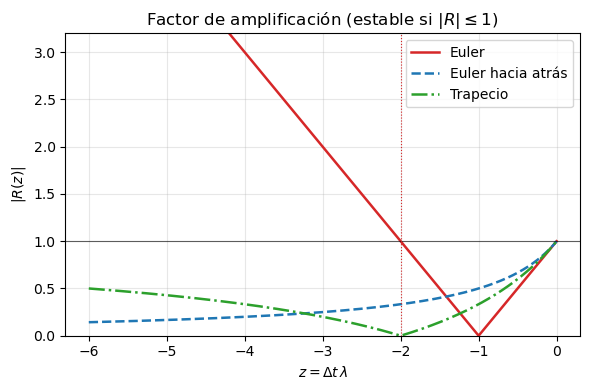

In [54]:
# Grafica del factor de ampliación |R(z)| de los esquemas temporales
fig, ax = plt.subplots(figsize=(6, 4))
z = np.linspace(-6, 0, 600)
ax.plot(z, np.abs(1 + z),                  color='tab:red',   lw=1.8, label='Euler')
ax.plot(z, np.abs(1/(1 - z)),              color='tab:blue',  lw=1.8, ls='--', label='Euler hacia atrás')
ax.plot(z, np.abs((1 + z/2)/(1 - z/2)),    color='tab:green', lw=1.8, ls='-.', label='Trapecio')
ax.axhline(1, color='k', lw=0.8, alpha=0.6)
ax.axvline(-2, color='tab:red', lw=0.8, ls=':')
ax.set_ylim(0, 3.2)
ax.set_xlabel(r'$z=\Delta t\,\lambda$'); ax.set_ylabel(r'$|R(z)|$')
ax.set_title('Factor de amplificación (estable si $|R|\\leq1$)')
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig('figuras/t6_amplificacion.pdf', bbox_inches='tight')
print('Guardada: figuras/t6_amplificacion.pdf')
plt.show()

In [55]:
# Config
CLAVES = ['euler', 'euler_imp', 'trapecio']
NOMBRE = {'euler': 'Euler', 'euler_imp': 'Euler hacia atrás', 'trapecio': 'Trapecio'}
ESTILO = {'euler':     dict(color='tab:red',   marker='o', ls='-'),
          'euler_imp': dict(color='tab:blue',  marker='^', ls='--'),
          'trapecio':  dict(color='tab:green', marker='s', ls='-.')}

def integrar(metodo, A, U0, T, nsteps, exacta=None, guardar=(), tope=1e3, rapido=False):
    """
    Integra dU/dt = A U de t=0 a t=T con nsteps pasos de tamaño dt=T/nsteps.
    tope   : si max|U| lo supera (o aparece un valor no finito) se detiene y se marca como divergente
    """
    N = len(U0)
    dt = T/nsteps
    I = sps.identity(N, format='csc')
    t0 = time.perf_counter()

    # Euler explicito
    if metodo == 'euler':
        M = (I + dt*A).tocsr()
        paso = lambda U: M @ U
    # Euler hacia atras
    elif metodo == 'euler_imp':
        lu = spla.splu((I - dt*A).tocsc())         # se factoriza una sola vez
        paso = lu.solve
    # Trapecio
    elif metodo == 'trapecio':
        lu = spla.splu((I - 0.5*dt*A).tocsc())      # se factoriza una sola vez
        B = (I + 0.5*dt*A).tocsr()
        paso = lambda U: lu.solve(B @ U)
    else:
        raise ValueError(metodo)

    # Inicialización
    U = U0.copy()
    err, snaps, explota = None, {}, None
    #Bucle de integración
    with np.errstate(all='ignore'):
        if rapido:
            for _ in range(nsteps):
                U = paso(U)
        else:
            guardar = set(int(k) for k in guardar)
            if exacta is not None:
                err = np.full(nsteps + 1, np.nan)
                err[0] = np.max(np.abs(U - exacta(0.0)))
            if 0 in guardar: snaps[0] = U.copy()
            for n in range(1, nsteps + 1):
                U = paso(U)
                if exacta is not None:
                    err[n] = np.max(np.abs(U - exacta(n*dt)))
                if n in guardar: snaps[n] = U.copy()
                if (not np.all(np.isfinite(U))) or np.max(np.abs(U)) > tope:
                    explota = n
                    break
    # Calculo de tiempo y retorno
    cpu = time.perf_counter() - t0
    return dict(U=U, cpu=cpu, err=err, snaps=snaps, explota=explota, dt=dt, nsteps=nsteps)

## 4. Validación del código

Como $\mathbf{U}(0)=\mathbf{v}_1$, el resultado de cada método en $t=T$ debe coincidir con $R(\Delta t\,\lambda_1)^n\mathbf{v}_1$ hasta redondeo. Se comprueba con $\Delta t=h^2/2$ para los cuatro valores de $N$.

In [56]:
# Factor de amplificación R(z) como funciones
R = {'euler':     lambda z: 1 + z,
     'euler_imp': lambda z: 1/(1 - z),
     'trapecio':  lambda z: (1 + z/2)/(1 - z/2)}

print(f"{'N':>5}{'pasos':>8}" + ''.join(f"{NOMBRE[m]:>20}" for m in CLAVES))
for N in NS:
    h, x = malla(N); A = matriz_A(N); U0 = f0(x)
    n = int(np.ceil(T/(h**2/2))); dt = T/n
    fila = []
    for m in CLAVES:
        U = integrar(m, A, U0, T, n)['U']
        cerrada = R[m](dt*lam1(N))**n * U0
        fila.append(np.max(np.abs(U - cerrada))/np.max(np.abs(cerrada)))
    print(f"{N:>5}{n:>8}" + ''.join(f"{v:>20.2e}" for v in fila))
print("\n(diferencia relativa entre el código y la fórmula cerrada R^n v1; debe estar al nivel del redondeo)")

    N   pasos               Euler   Euler hacia atrás            Trapecio
   25    1352            3.72e-14            8.76e-14            1.05e-14
   50    5202            1.38e-13            5.09e-13            3.31e-13
  100   20402            1.35e-12            6.55e-12            1.14e-13
  150   45602            6.35e-14            5.20e-13            2.76e-12

(diferencia relativa entre el código y la fórmula cerrada R^n v1; debe estar al nivel del redondeo)


## 5. Resultados con $\Delta t\approx h^2/2$

Para cada $N$ se integra hasta $T=1$ con los tres métodos y se guarda el error máximo en cada paso. Se miden en $t=1$ dos normas del error respecto a la solución exacta de la EDP, la **norma máxima** $\lVert\mathbf{e}\rVert_\infty=\max_i|U_i-u(x_i,T)|$ y la **norma $L^2$ discreta** $\lVert\mathbf{e}\rVert_{2,h}=\sqrt{h\sum_i e_i^2}$.

In [57]:
# Normas de error
def err_max(e):  return np.max(np.abs(e))
def err_l2(e, h): return np.sqrt(h*np.sum(e**2))

# Simulaciones
TIEMPOS_SNAP = [0.05, 0.1, 0.25, 0.5, 1.0]
res, par = {}, {}
t0 = time.time()
for N in NS:
    h, x = malla(N); A = matriz_A(N); U0 = f0(x)
    n = int(np.ceil(T/(h**2/2))); dt = T/n
    par[N] = dict(h=h, x=x, n=n, dt=dt, ratio=dt/(h**2/2))
    ex = lambda t, s=U0: np.exp(-D*np.pi**2*t)*s            # Solución exacta
    guardar = set(np.linspace(0, n, 201).astype(int)) | {int(round(t*n/T)) for t in TIEMPOS_SNAP}
    for m in CLAVES:
        res[(N, m)] = integrar(m, A, U0, T, n, exacta=ex, guardar=guardar)
    print(f"N = {N:>3} listo ({time.time()-t0:.1f} s)")

print()
print(f"{'N':>5}{'h':>11}{'Δt':>11}{'pasos':>8}{'Δt/(h²/2)':>12}")
for N in NS:
    p = par[N]
    print(f"{N:>5}{p['h']:>11.5f}{p['dt']:>11.3e}{p['n']:>8}{p['ratio']:>12.4f}")

guardar_tabla('t6_parametros', ['$N$', '$h$', r'$\Delta t$', 'Pasos', r'$\Delta t/(h^2/2)$'],
              [[f"${N}$", sci(par[N]['h'], 3), sci(par[N]['dt'], 3), f"${par[N]['n']}$", f"${par[N]['ratio']:.4f}$"] for N in NS],
              'r r r r r')

N =  25 listo (0.1 s)
N =  50 listo (0.3 s)
N = 100 listo (1.4 s)
N = 150 listo (4.0 s)

    N          h         Δt   pasos   Δt/(h²/2)
   25    0.03846  7.396e-04    1352      1.0000
   50    0.01961  1.922e-04    5202      1.0000
  100    0.00990  4.901e-05   20402      1.0000
  150    0.00662  2.193e-05   45602      1.0000
Guardada: tablas/t6_parametros.tex


In [58]:
# Errores
emax, el2, erel = {}, {}, {}
for N in NS:
    h, x = par[N]['h'], par[N]['x']
    u_ex = u_exacta(x, T)
    for m in CLAVES:
        e = res[(N, m)]['U'] - u_ex
        emax[(N, m)] = err_max(e)
        el2[(N, m)]  = err_l2(e, h)
        erel[(N, m)] = err_max(e)/err_max(u_ex)

print("Error en norma máxima en t = 1  (solución exacta máx = %.3e)" % np.exp(-np.pi**2*T))
print(f"{'N':>5}" + ''.join(f"{NOMBRE[m]:>20}" for m in CLAVES))
for N in NS:
    print(f"{N:>5}" + ''.join(f"{emax[(N, m)]:>20.3e}" for m in CLAVES))
print("\nError en norma L2 discreta en t = 1")
for N in NS:
    print(f"{N:>5}" + ''.join(f"{el2[(N, m)]:>20.3e}" for m in CLAVES))
print("\nError relativo (norma máxima / máx de la exacta) en t = 1")
for N in NS:
    print(f"{N:>5}" + ''.join(f"{erel[(N, m)]:>20.3e}" for m in CLAVES))

enc = ['$N$'] + [NOMBRE[m] for m in CLAVES]
guardar_tabla('t6_error_max', enc, [[f"${N}$"] + [sci(emax[(N, m)]) for m in CLAVES] for N in NS], 'r r r r')
guardar_tabla('t6_error_l2',  enc, [[f"${N}$"] + [sci(el2[(N, m)])  for m in CLAVES] for N in NS], 'r r r r')
guardar_tabla('t6_error_rel', enc, [[f"${N}$"] + [sci(erel[(N, m)]) for m in CLAVES] for N in NS], 'r r r r')

Error en norma máxima en t = 1  (solución exacta máx = 5.172e-05)
    N               Euler   Euler hacia atrás            Trapecio
   25           1.232e-06           2.531e-06           6.222e-07
   50           3.220e-07           6.485e-07           1.614e-07
  100           8.226e-08           1.648e-07           4.116e-08
  150           3.682e-08           7.369e-08           1.841e-08

Error en norma L2 discreta en t = 1
   25           8.712e-07           1.789e-06           4.400e-07
   50           2.278e-07           4.588e-07           1.142e-07
  100           5.818e-08           1.166e-07           2.911e-08
  150           2.604e-08           5.211e-08           1.302e-08

Error relativo (norma máxima / máx de la exacta) en t = 1
   25           2.382e-02           4.892e-02           1.203e-02
   50           6.229e-03           1.254e-02           3.122e-03
  100           1.591e-03           3.187e-03           7.958e-04
  150           7.119e-04           1.425e-03 

### Orden de convergencia en $h$

Con $\Delta t\propto h^2$ el error total debería ser $O(h^2)$ para los tres métodos (en Euler y en Euler hacia atrás el término temporal es $O(\Delta t)=O(h^2)$, y en Trapecio es $O(\Delta t^2)=O(h^4)$ y queda dominado por el espacial). El orden observado entre dos mallas es
$$
p=\frac{\ln(e_{N_1}/e_{N_2})}{\ln(h_1/h_2)}.
$$

In [59]:
# Orden de Convergencia
pares = [(25, 50), (50, 100), (100, 150)]
def orden_h(e1, e2, h1, h2):
    return np.log(e1/e2)/np.log(h1/h2)

filas_ord, ord_h = [], {}
print(f"{'N1→N2':>10}" + ''.join(f"{NOMBRE[m]:>20}" for m in CLAVES))
for N1, N2 in pares:
    h1, h2 = par[N1]['h'], par[N2]['h']
    v = [orden_h(emax[(N1, m)], emax[(N2, m)], h1, h2) for m in CLAVES]
    ord_h[(N1, N2)] = v
    print(f"{str(N1)+'→'+str(N2):>10}" + ''.join(f"{x:>20.3f}" for x in v))
    filas_ord.append([f"${N1}\\to{N2}$"] + [f"${x:.2f}$" for x in v])
guardar_tabla('t6_orden_h', ['$N_1\\to N_2$'] + [NOMBRE[m] for m in CLAVES], filas_ord, 'l r r r')

     N1→N2               Euler   Euler hacia atrás            Trapecio
     25→50               1.992               2.021               2.003
    50→100               1.997               2.005               2.000
   100→150               1.999               2.002               2.000
Guardada: tablas/t6_orden_h.tex


### Descomposición del error: parte espacial y parte temporal

Con la solución exacta del sistema de EDOs, $\mathbf{U}(T)=e^{\lambda_1T}\mathbf{v}_1$ (sección 2), el error total en $t=T$ se separa en dos:

* **Error espacial:** $\lVert\mathbf{U}(T)-\mathbf{u}(T)\rVert_\infty$ (lo que se comete solo por discretizar en $x$, aunque se integrara el tiempo sin error).
* **Error temporal:** $\lVert\mathbf{U}_n-\mathbf{U}(T)\rVert_\infty$ para cada método (lo que se comete solo por integrar en $t$).

Además, de los desarrollos de $\lambda_1$ y de $R$ se obtiene una **predicción** del error relativo con signo $(U_n/u-1)$ en el primer orden en $h^2$ y $\Delta t$ (con $\lambda\approx-\pi^2$):

$$
\text{Euler: }\ \pi^4T\left(\tfrac{h^2}{12}-\tfrac{\Delta t}{2}\right),\qquad
\text{Euler hacia atrás: }\ \pi^4T\left(\tfrac{h^2}{12}+\tfrac{\Delta t}{2}\right),\qquad
\text{Trapecio: }\ \pi^4T\tfrac{h^2}{12}-\pi^6T\tfrac{\Delta t^2}{12}.
$$

El primer término es el espacial. El temporal tiene signo opuesto en Euler (la solución numérica decae demasiado rápido) y en Euler hacia atrás (decae demasiado lento), por lo que en Euler los dos efectos se restan parcialmente. En Trapecio el término temporal también resta a la parte espacial, pero es de orden $\Delta t^2$ y con $\Delta t=h^2/2$ es despreciable.

In [60]:
# Error espacial vs. temporal
esp, temp, rel_med, rel_pred = {}, {}, {}, {}
for N in NS:
    h, x, n, dt = par[N]['h'], par[N]['x'], par[N]['n'], par[N]['dt']
    U_edo = np.exp(lam1(N)*T)*f0(x)
    u_ex  = u_exacta(x, T)
    esp[N] = err_max(U_edo - u_ex)
    for m in CLAVES:
        temp[(N, m)] = err_max(res[(N, m)]['U'] - U_edo)               # error temporal puro
        rel_med[(N, m)] = (res[(N, m)]['U'][N//2]/u_ex[N//2]) - 1      # error relativo con signo (cociente constante en x)
    c = np.pi**4*T
    rel_pred[(N, 'euler')]     = c*(h**2/12 - dt/2)
    rel_pred[(N, 'euler_imp')] = c*(h**2/12 + dt/2)
    rel_pred[(N, 'trapecio')]  = c*h**2/12 - np.pi**6*T*dt**2/12

print("Descomposición en t = 1 (norma máxima)")
print(f"{'N':>5}{'espacial':>12}" + ''.join(f"{'temporal '+NOMBRE[m]:>26}" for m in CLAVES))
for N in NS:
    print(f"{N:>5}{esp[N]:>12.3e}" + ''.join(f"{temp[(N, m)]:>26.3e}" for m in CLAVES))

print("\nError relativo con signo: medido / predicho (primer orden)")
print(f"{'N':>5}" + ''.join(f"{NOMBRE[m]:>30}" for m in CLAVES))
for N in NS:
    print(f"{N:>5}" + ''.join(f"{rel_med[(N, m)]:>16.3e} /{rel_pred[(N, m)]:>11.3e}" for m in CLAVES))

guardar_tabla('t6_descomp', ['$N$', 'Espacial'] + [f'Temporal, {NOMBRE[m]}' for m in CLAVES],
              [[f"${N}$", sci(esp[N])] + [sci(temp[(N, m)]) for m in CLAVES] for N in NS], 'r r r r r')

def sgn(v):  # número con signo para la tabla
    m, e = f"{v:.2e}".split('e')
    return f"${m}\\times10^{{{int(e)}}}$"
guardar_tabla('t6_prediccion', ['$N$'] + [f'{NOMBRE[m]} (medido / predicho)' for m in CLAVES],
              [[f"${N}$"] + [f"{sgn(rel_med[(N, m)])} / {sgn(rel_pred[(N, m)])}" for m in CLAVES] for N in NS], 'r l l l')

Descomposición en t = 1 (norma máxima)
    N    espacial            temporal Eulertemporal Euler hacia atrás         temporal Trapecio
   25   6.245e-07                 1.857e-06                 1.906e-06                 2.286e-09
   50   1.616e-07                 4.836e-07                 4.869e-07                 1.534e-10
  100   4.117e-08                 1.234e-07                 1.236e-07                 9.960e-12
  150   1.842e-08                 5.523e-08                 5.528e-08                 1.993e-12

Error relativo con signo: medido / predicho (primer orden)
    N                         Euler             Euler hacia atrás                      Trapecio
   25      -2.382e-02 / -2.402e-02       4.892e-02 /  4.803e-02       1.203e-02 /  1.196e-02
   50      -6.229e-03 / -6.242e-03       1.254e-02 /  1.248e-02       3.122e-03 /  3.118e-03
  100      -1.591e-03 / -1.591e-03       3.187e-03 /  3.183e-03       7.958e-04 /  7.956e-04
  150      -7.119e-04 / -7.120e-04       1.425

### Figuras

Se grafican: el error contra $h$ en escala logarítmica, la evolución del error máximo en el tiempo (absoluto y relativo) para cada $N$, algunos perfiles de la solución y del error, y el mapa de calor de la solución exacta.

Guardada: figuras/t6_error_h.pdf


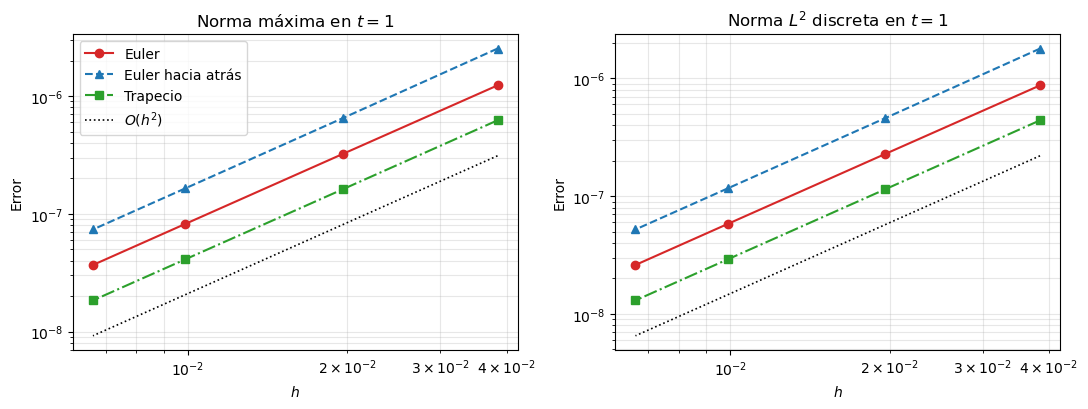

In [61]:
# Error en t = 1 contra h 
hs = np.array([par[N]['h'] for N in NS])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, dic, tit in [(axs[0], emax, r'Norma máxima en $t=1$'), (axs[1], el2, r'Norma $L^2$ discreta en $t=1$')]:
    for m in CLAVES:
        ax.loglog(hs, [dic[(N, m)] for N in NS], ms=6, label=NOMBRE[m], **ESTILO[m])
    ref = emax[(NS[0], 'trapecio')] if dic is emax else el2[(NS[0], 'trapecio')]
    ax.loglog(hs, 0.5*ref*(hs/hs[0])**2, 'k:', lw=1.2, label=r'$O(h^2)$')
    ax.set_xlabel(r'$h$'); ax.set_ylabel('Error'); ax.set_title(tit); ax.grid(alpha=0.3, which='both')
axs[0].legend()
fig.tight_layout()
fig.savefig('figuras/t6_error_h.pdf', bbox_inches='tight')
print('Guardada: figuras/t6_error_h.pdf')
plt.show()

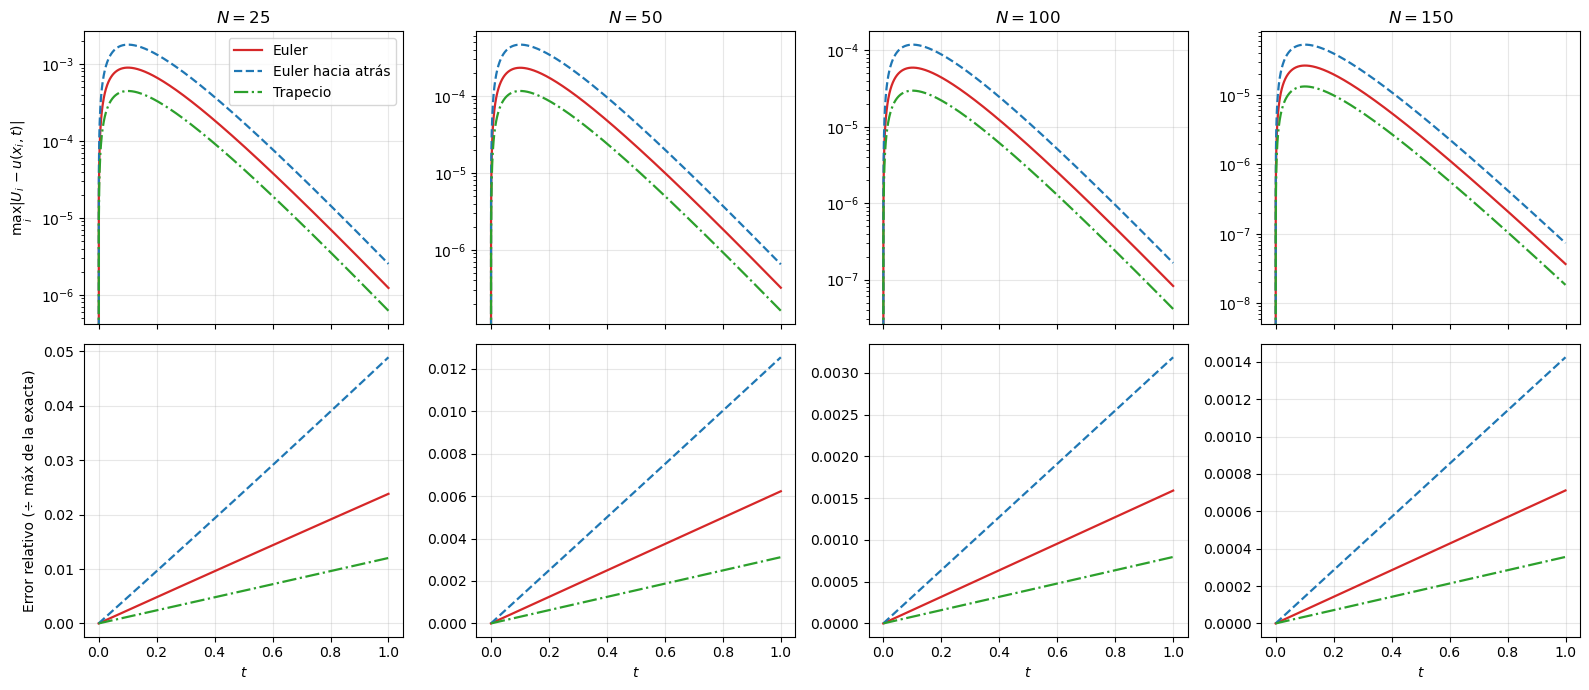

Guardada: figuras/t6_error_tiempo.pdf


In [62]:
# Error máximo en el tiempo (absoluto y relativo)
fig, axs = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for j, N in enumerate(NS):
    n, dt = par[N]['n'], par[N]['dt']
    t = np.arange(n + 1)*dt
    escala = np.exp(-np.pi**2*t)
    for m in CLAVES:
        e = res[(N, m)]['err']
        axs[0, j].semilogy(t, e, lw=1.6, color=ESTILO[m]['color'], ls=ESTILO[m]['ls'], label=NOMBRE[m])
        axs[1, j].plot(t, e/escala, lw=1.6, color=ESTILO[m]['color'], ls=ESTILO[m]['ls'])
    axs[0, j].set_title(f'$N={N}$'); axs[0, j].grid(alpha=0.3)
    axs[1, j].set_xlabel('$t$'); axs[1, j].grid(alpha=0.3)
axs[0, 0].set_ylabel(r'$\max_i|U_i-u(x_i,t)|$'); axs[1, 0].set_ylabel('Error relativo (÷ máx de la exacta)')
axs[0, 0].legend()
fig.tight_layout()
plt.show()

# EXTRA para guardar la figura en 2x4 para el formato de LATEX
fig2, axs2 = plt.subplots(4, 2, figsize=(10, 14), sharex=True)
for j, N in enumerate(NS):
    n, dt = par[N]['n'], par[N]['dt']
    t = np.arange(n + 1)*dt
    escala = np.exp(-np.pi**2*t)
    col = j // 2                 
    fila = 2 * (j % 2)           
    ax_abs = axs2[fila,     col]
    ax_rel = axs2[fila + 1, col]
    for m in CLAVES:
        e = res[(N, m)]['err']
        ax_abs.semilogy(t, e, lw=1.6, color=ESTILO[m]['color'], ls=ESTILO[m]['ls'], label=NOMBRE[m])
        ax_rel.plot(t, e/escala, lw=1.6, color=ESTILO[m]['color'], ls=ESTILO[m]['ls'])
    ax_abs.set_title(f'$N={N}$'); ax_abs.grid(alpha=0.3)
    ax_rel.set_xlabel('$t$'); ax_rel.grid(alpha=0.3)
axs2[0, 0].set_ylabel(r'$\max_i|U_i-u(x_i,t)|$')
axs2[1, 0].set_ylabel('Error relativo (÷ máx de la exacta)')
axs2[0, 0].legend()
fig2.tight_layout()
fig2.savefig('figuras/t6_error_tiempo.pdf', bbox_inches='tight')

plt.close(fig2)

print('Guardada: figuras/t6_error_tiempo.pdf')

Guardada: figuras/t6_perfiles.pdf


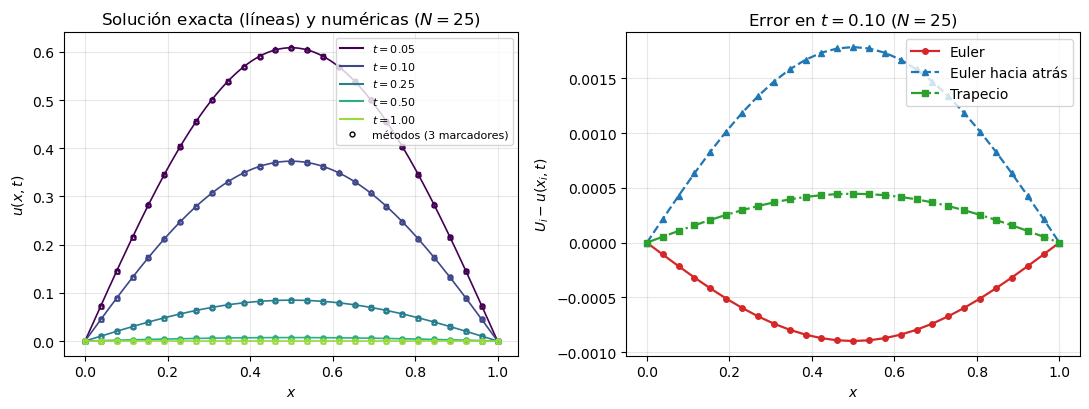

In [63]:
# Perfiles de la solución (N = 25) y del error
N = 25
n, dt, x = par[N]['n'], par[N]['dt'], par[N]['x']
xf = np.linspace(0, 1, 400)
xc = np.concatenate([[0], x, [1]])                       # nodos con las fronteras
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
cols = plt.cm.viridis(np.linspace(0, 0.85, len(TIEMPOS_SNAP)))
for c, tt in zip(cols, TIEMPOS_SNAP):
    k = int(round(tt*n/T)); t_k = k*dt
    axs[0].plot(xf, u_exacta(xf, t_k), color=c, lw=1.2)
    for m, mk, off in [('euler', 'o', 0), ('euler_imp', '^', 0), ('trapecio', 's', 0)]:
        U = np.concatenate([[0], res[(N, m)]['snaps'][k], [0]])
        axs[0].plot(xc, U, mk, color=c, ms=3.5, mfc='none', ls='none')
    axs[0].plot([], [], color=c, label=f'$t={t_k:.2f}$')
axs[0].plot([], [], 'ko', ms=3.5, mfc='none', ls='none', label='métodos (3 marcadores)')
axs[0].set_xlabel('$x$'); axs[0].set_ylabel('$u(x,t)$'); axs[0].set_title(f'Solución exacta (líneas) y numéricas ($N={N}$)')
axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3)

k = int(round(0.1*n/T)); t_k = k*dt
for m in CLAVES:
    e = np.concatenate([[0], res[(N, m)]['snaps'][k] - u_exacta(x, t_k), [0]])
    axs[1].plot(xc, e, lw=1.6, color=ESTILO[m]['color'], ls=ESTILO[m]['ls'], marker=ESTILO[m]['marker'], ms=4, label=NOMBRE[m])
axs[1].set_xlabel('$x$'); axs[1].set_ylabel(r'$U_i-u(x_i,t)$'); axs[1].set_title(f'Error en $t={t_k:.2f}$ ($N={N}$)')
axs[1].legend(); axs[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig('figuras/t6_perfiles.pdf', bbox_inches='tight')
print('Guardada: figuras/t6_perfiles.pdf')
plt.show()

## 6. Estabilidad: ¿qué pasa con $\Delta t>h^2/2$?

Se fija $N=50$ ($h^2/2\approx1.92\times10^{-4}$) y se repite el cálculo con pasos $\Delta t=\varrho\,h^2/2$ para varias razones $\varrho$ (el número de pasos es $n=\lceil T/\Delta t\rceil$, por lo que la razón real queda apenas por debajo). Se detiene la corrida si el máximo de $|U|$ pasa de $10^3$ (la solución exacta nunca supera $1$), y en ese caso el método se marca como **divergente**.

La condición inicial es un vector propio, por lo que los modos de alta frecuencia que desestabilizan a Euler solo nacen del **redondeo**, que ya basta para que crezcan geométricamente con factor $|R|=|1+\Delta t\lambda_N|>1$ en cuanto $\varrho>1$.

In [64]:
N = 50
h, x = malla(N); A = matriz_A(N); U0 = f0(x)
ex = lambda t: np.exp(-D*np.pi**2*t)*U0
razones = [0.5, 1.0, 1.05, 1.5, 10, 100, 1000]
est = {}
for rho in razones:
    n = int(np.ceil(T/(rho*h**2/2)))
    for m in CLAVES:
        est[(rho, m)] = integrar(m, A, U0, T, n, exacta=ex)

def txt_est(rho, m):
    r = est[(rho, m)]
    if r['explota'] is not None:
        return f"diverge ($t\\approx{r['explota']*r['dt']:.2f}$)"
    return sci(np.max(np.abs(r['U'] - u_exacta(x, T))))

print(f"{'ϱ real':>9}{'Δt':>11}{'pasos':>8}" + ''.join(f"{NOMBRE[m]:>26}" for m in CLAVES))
filas_est = []
for rho in razones:
    r0 = est[(rho, 'euler')]
    ratio = r0['dt']/(h**2/2)
    fila = []
    for m in CLAVES:
        r = est[(rho, m)]
        fila.append(f"diverge (t≈{r['explota']*r['dt']:.2f})" if r['explota'] is not None
                    else f"{np.max(np.abs(r['U'] - u_exacta(x, T))):.3e}")
    print(f"{ratio:>9.3f}{r0['dt']:>11.3e}{r0['nsteps']:>8}" + ''.join(f"{v:>26}" for v in fila))
    filas_est.append([f"${ratio:.2f}$", sci(r0['dt']), f"${r0['nsteps']}$"] + [txt_est(rho, m) for m in CLAVES])
guardar_tabla('t6_estabilidad', [r'$\Delta t/(h^2/2)$', r'$\Delta t$', 'Pasos'] + [NOMBRE[m] for m in CLAVES],
              filas_est, 'r r r r r r')

   ϱ real         Δt   pasos                     Euler         Euler hacia atrás                  Trapecio
    0.500  9.612e-05   10404                 8.063e-08                 4.046e-07                 1.615e-07
    1.000  1.922e-04    5202                 3.220e-07                 6.485e-07                 1.614e-07
    1.050  2.018e-04    4955          diverge (t≈0.10)                 6.728e-07                 1.614e-07
    1.500  2.884e-04    3468          diverge (t≈0.02)                 8.932e-07                 1.612e-07
    9.985  1.919e-03     521          diverge (t≈0.03)                 5.174e-06                 1.463e-07
   98.151  1.887e-02      53          diverge (t≈0.17)                 6.584e-05                 1.303e-06
  867.000  1.667e-01       6          diverge (t≈1.00)                 2.871e-03                 5.084e-05
Guardada: tablas/t6_estabilidad.tex


Guardada: figuras/t6_estabilidad.pdf


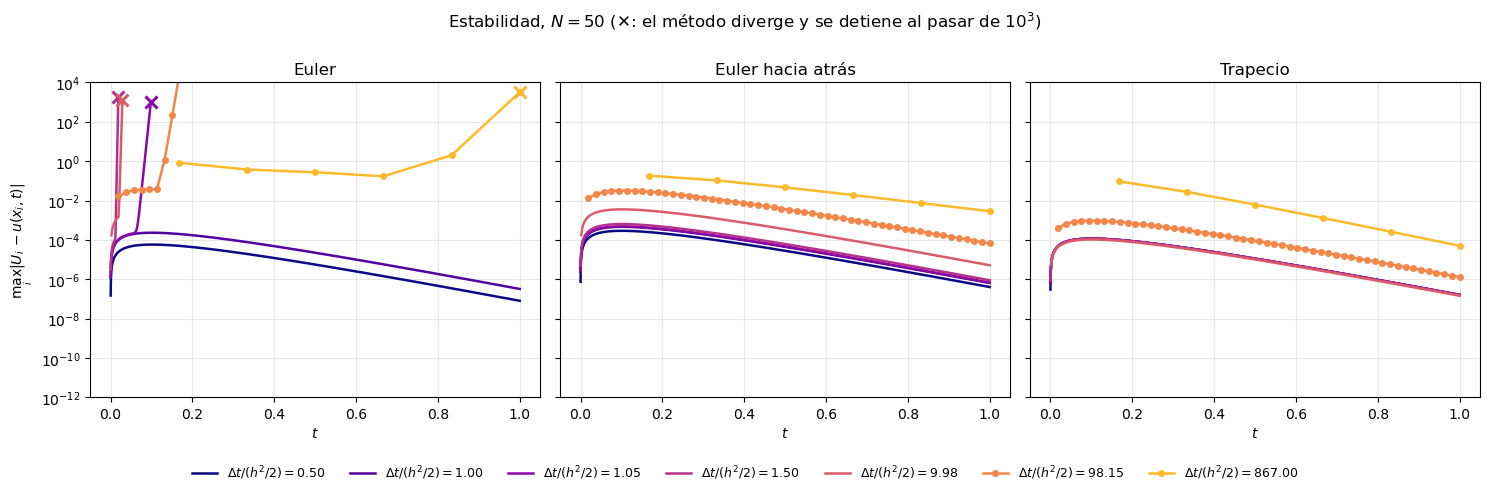

In [65]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
cmap = plt.cm.plasma(np.linspace(0, 0.85, len(razones)))
for ax, m in zip(axs, CLAVES):
    for c, rho in zip(cmap, razones):
        r = est[(rho, m)]
        ult = r['explota'] if r['explota'] is not None else r['nsteps']
        t = np.arange(1, ult + 1)*r['dt']                 # sin el punto t = 0 (error 0)
        e = r['err'][1:ult + 1]
        ratio = r['dt']/(h**2/2)
        ax.semilogy(t, e, color=c, lw=1.8, marker='o' if r['nsteps'] < 60 else None, ms=4,
                    label=rf'$\Delta t/(h^2/2)={ratio:.2f}$')
        if r['explota'] is not None:
            ax.plot(t[-1], e[-1], 'x', color=c, ms=9, mew=2.2)       # ✕ = divergió
    ax.set_title(NOMBRE[m]); ax.set_xlabel('$t$'); ax.grid(alpha=0.3); ax.set_ylim(1e-12, 1e4)
axs[0].set_ylabel(r'$\max_i|U_i-u(x_i,t)|$')
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=len(razones), fontsize=9, frameon=False)
fig.suptitle(f'Estabilidad, $N={N}$ (✕: el método diverge y se detiene al pasar de $10^3$)', y=1.0)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig('figuras/t6_estabilidad.pdf', bbox_inches='tight')
print('Guardada: figuras/t6_estabilidad.pdf')
plt.show()

## 7. Orden de convergencia en $\Delta t$

Para ver el orden temporal sin que lo tape el error espacial se fija $N=25$ y se compara contra la solución exacta **del sistema de EDOs** (error puramente temporal), con $n=10,20,40,\dots,40\,960$ pasos. Euler es inestable para $\Delta t>h^2/2\approx7.4\times10^{-4}$, es decir, para $n<1352$; en esos casos se corre igual y se marca la divergencia. El error se mide relativo al máximo de la solución exacta en $T$, y el orden observado entre un paso y su mitad es $p=\log_2(e_{\Delta t}/e_{\Delta t/2})$.

Para ver qué pasa con el error total, se grafica también el error contra la solución exacta **de la EDP**: ahí aparece un piso, el error espacial, que ningún refinamiento de $\Delta t$ elimina. En Euler y en Trapecio se ve además una caída local: es donde el error temporal, de signo contrario al espacial, lo cancela casi por completo (sección 5).

In [66]:
N = 25
h, x = malla(N); A = matriz_A(N); U0 = f0(x)
U_edo = np.exp(lam1(N)*T)*U0
u_ex  = u_exacta(x, T)
NSTEPS = [10*2**k for k in range(13)]                     # 10, 20, ..., 40960
e_edo, e_pde = {}, {}
for n in NSTEPS:
    for m in CLAVES:
        r = integrar(m, A, U0, T, n)
        if r['explota'] is not None:
            e_edo[(n, m)] = e_pde[(n, m)] = np.nan
        else:
            e_edo[(n, m)] = err_max(r['U'] - U_edo)/err_max(U_edo)
            e_pde[(n, m)] = err_max(r['U'] - u_ex)/err_max(u_ex)

def orden_dt(n, m):
    a, b = e_edo.get((n, m), np.nan), e_edo.get((2*n, m), np.nan)
    return np.log2(a/b) if np.isfinite(a) and np.isfinite(b) else np.nan

print(f"Error temporal relativo (N = {N}, h²/2 = {h**2/2:.2e}, estable en Euler si Δt ≤ h²/2, es decir n ≥ {int(np.ceil(T/(h**2/2)))})")
print(f"{'pasos':>7}{'Δt':>11}" + ''.join(f"{NOMBRE[m]:>22}{'p':>7}" for m in CLAVES))
filas_dt = []
for n in NSTEPS:
    fila, fila_tex = [], [f"${n}$", sci(T/n, 2)]
    for m in CLAVES:
        e, p = e_edo[(n, m)], orden_dt(n, m)
        fila.append(f"{('inestable' if np.isnan(e) else f'{e:.3e}'):>22}{('' if np.isnan(p) else f'{p:.2f}'):>7}")
        fila_tex += ['inestable' if np.isnan(e) else sci(e), '---' if np.isnan(p) else f"${p:.2f}$"]
    print(f"{n:>7}{T/n:>11.3e}" + ''.join(fila))
    filas_dt.append(fila_tex)
guardar_tabla('t6_orden_dt', ['Pasos', r'$\Delta t$', 'Euler', '$p$', 'E. atrás', '$p$', 'Trapecio', '$p$'], filas_dt, 'r r r r r r r r')

Error temporal relativo (N = 25, h²/2 = 7.40e-04, estable en Euler si Δt ≤ h²/2, es decir n ≥ 1352)
  pasos         Δt                 Euler      p     Euler hacia atrás      p              Trapecio      p
     10  1.000e-01             inestable                    1.904e+01   1.84             6.092e-01   1.70
     20  5.000e-02             inestable                    5.318e+00   1.53             1.871e-01   1.93
     40  2.500e-02             inestable                    1.846e+00   1.29             4.910e-02   1.98
     80  1.250e-02             inestable                    7.535e-01   1.15             1.242e-02   2.00
    160  6.250e-03             inestable                    3.388e-01   1.08             3.115e-03   2.00
    320  3.125e-03             inestable                    1.604e-01   1.04             7.793e-04   2.00
    640  1.563e-03             inestable                    7.804e-02   1.02             1.949e-04   2.00
   1280  7.813e-04             inestable            

Guardada: figuras/t6_orden_dt.pdf


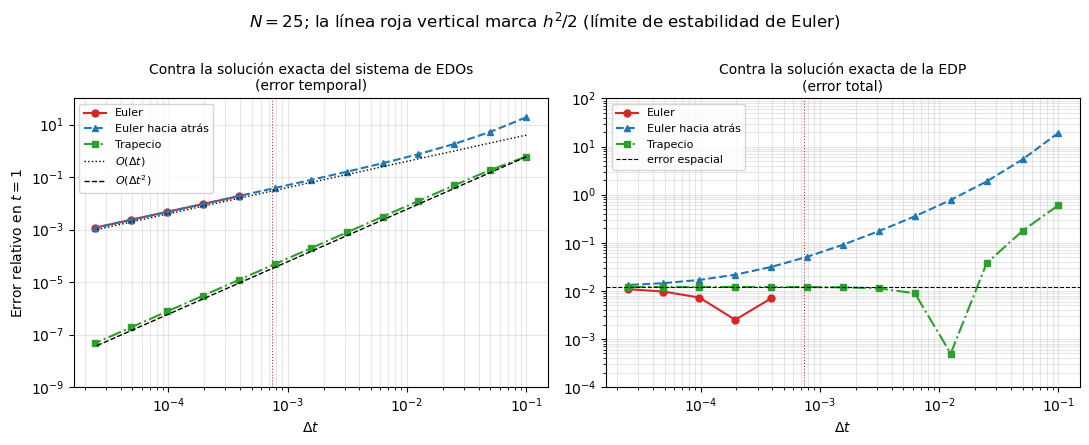

In [67]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
dts = np.array([T/n for n in NSTEPS])
for ax, dic, tit in [(axs[0], e_edo, 'Contra la solución exacta del sistema de EDOs\n(error temporal)'),
                     (axs[1], e_pde, 'Contra la solución exacta de la EDP\n(error total)')]:
    for m in CLAVES:
        y = np.array([dic[(n, m)] for n in NSTEPS])
        ax.loglog(dts, y, ms=5, label=NOMBRE[m], **ESTILO[m])
    ax.axvline(h**2/2, color='tab:red', lw=0.8, ls=':')
    ax.set_xlabel(r'$\Delta t$'); ax.set_title(tit, fontsize=10); ax.grid(alpha=0.3, which='both')
axs[0].loglog(dts, 40*dts, 'k:', lw=1.0, label=r'$O(\Delta t)$')
axs[0].loglog(dts, 60*dts**2, 'k--', lw=1.0, label=r'$O(\Delta t^2)$')
axs[1].axhline(abs(np.exp(lam1(N)*T)/np.exp(-np.pi**2*T) - 1), color='k', lw=0.8, ls='--', label='error espacial')
axs[0].set_ylabel('Error relativo en $t=1$'); axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
axs[0].set_ylim(1e-9, 1e2); axs[1].set_ylim(1e-4, 1e2)
fig.suptitle(f'$N={N}$; la línea roja vertical marca $h^2/2$ (límite de estabilidad de Euler)', y=1.0)
fig.tight_layout()
fig.savefig('figuras/t6_orden_dt.pdf', bbox_inches='tight')
print('Guardada: figuras/t6_orden_dt.pdf')
plt.show()

## 8. Costo computacional

Se mide el tiempo de CPU de cada método con $\Delta t\approx h^2/2$ (incluye armar las matrices y, en los implícitos, factorizar), usando un lazo sin ninguna revisión y tomando el mejor de 3 repeticiones. Los tiempos dependen del equipo, solo importan los órdenes de magnitud y las proporciones.

In [68]:
cpu = {}
for N in NS:
    h, x = malla(N); A = matriz_A(N); U0 = f0(x); n = par[N]['n']
    for m in CLAVES:
        cpu[(N, m)] = min(integrar(m, A, U0, T, n, rapido=True)['cpu'] for _ in range(3))

print(f"{'N':>5}{'pasos':>8}" + ''.join(f"{NOMBRE[m]:>20}" for m in CLAVES))
for N in NS:
    print(f"{N:>5}{par[N]['n']:>8}" + ''.join(f"{cpu[(N, m)]:>18.3f} s" for m in CLAVES))
guardar_tabla('t6_tiempos', ['$N$', 'Pasos'] + [NOMBRE[m] for m in CLAVES],
              [[f"${N}$", f"${par[N]['n']}$"] + [f"${cpu[(N, m)]:.3f}$\\,s" for m in CLAVES] for N in NS], 'r r r r r')

# Pasos necesarios para alcanzar un error temporal relativo dado (N = 25, contra la EDO exacta)
print("\nPasos (de la lista 10, 20, 40, ..., 40960) para que el error temporal relativo sea menor que ε (N = 25):")
filas_eps = []
for eps in [1e-2, 1e-3]:
    fila, fila_tex = [], [sci(eps, 0)]
    for m in CLAVES:
        ok = [n for n in NSTEPS if np.isfinite(e_edo[(n, m)]) and e_edo[(n, m)] < eps]
        fila.append(str(ok[0]) if ok else f"> {NSTEPS[-1]}")
        fila_tex.append(f"${ok[0]}$" if ok else f"$>{NSTEPS[-1]}$")
    print(f"  ε = {eps:.0e}: " + '   '.join(f"{NOMBRE[m]}: {v}" for m, v in zip(CLAVES, fila)))
    filas_eps.append(fila_tex)
guardar_tabla('t6_pasos_eps', [r'$\varepsilon$'] + [NOMBRE[m] for m in CLAVES], filas_eps, 'r r r r')

    N   pasos               Euler   Euler hacia atrás            Trapecio
   25    1352             0.004 s             0.005 s             0.009 s
   50    5202             0.014 s             0.019 s             0.035 s
  100   20402             0.056 s             0.090 s             0.151 s
  150   45602             0.130 s             0.239 s             0.389 s
Guardada: tablas/t6_tiempos.tex

Pasos (de la lista 10, 20, 40, ..., 40960) para que el error temporal relativo sea menor que ε (N = 25):
  ε = 1e-02: Euler: 5120   Euler hacia atrás: 5120   Trapecio: 160
  ε = 1e-03: Euler: > 40960   Euler hacia atrás: > 40960   Trapecio: 320
Guardada: tablas/t6_pasos_eps.tex


### Trapecio con $\Delta t\propto h$

Como Trapecio es de segundo orden en $\Delta t$ y es incondicionalmente estable, no necesita $\Delta t\approx h^2/2$: basta con que su error temporal no supere al espacial. Con la predicción de la sección 5, el término temporal $\pi^6T\Delta t^2/12$ es la fracción $\pi^2\Delta t^2/h^2$ del espacial $\pi^4Th^2/12$ (y con signo contrario), así que $\Delta t=h/10$ lo deja en cerca del $10\,\%$ del espacial. Se compara el error total de Trapecio con tres pasos: $\Delta t=h^2/2$ (el de los experimentos anteriores), $\Delta t=h/10$ y $\Delta t=h/\pi$.

El caso $\Delta t=h/\pi$ es especial: ahí los dos términos son iguales y de signo contrario, y se cancelan a primer orden. Es una **coincidencia de este problema** (solución de un solo modo, sin ninguna garantía para otra condición inicial), pero permite ver que el error espacial de la solución no es un piso fijo cuando se combina con el temporal.

In [69]:
etiquetas = [('h²/2', lambda h: int(np.ceil(T/(h**2/2)))),
             ('h/10', lambda h: int(np.ceil(10*T/h))),
             ('h/π',  lambda h: int(np.ceil(np.pi*T/h)))]
tr_h, filas_tr = {}, []
print(f"{'N':>5}" + ''.join(f"{'pasos '+e:>14}{'error '+e:>14}{'CPU '+e:>12}" for e, _ in etiquetas))
for N in NS:
    h, x = malla(N); A = matriz_A(N); U0 = f0(x); u_ex = u_exacta(x, T)
    fila, fila_tex = [], [f"${N}$"]
    for etq, fn in etiquetas:
        n = fn(h)
        U = integrar('trapecio', A, U0, T, n)['U']
        e = err_max(U - u_ex)
        c = min(integrar('trapecio', A, U0, T, n, rapido=True)['cpu'] for _ in range(3))
        tr_h[(N, etq)] = (n, e, c)
        fila.append(f"{n:>14}{e:>14.3e}{c:>11.3f}s")
        fila_tex += [f"${n}$", sci(e)]
    print(f"{N:>5}" + ''.join(fila))
    filas_tr.append(fila_tex)
guardar_tabla('t6_trapecio_h', ['$N$', r'Pasos ($h^2/2$)', r'Error ($h^2/2$)', r'Pasos ($h/10$)', r'Error ($h/10$)', r'Pasos ($h/\pi$)', r'Error ($h/\pi$)'],
              filas_tr, 'r r r r r r r')

    N    pasos h²/2    error h²/2    CPU h²/2    pasos h/10    error h/10    CPU h/10     pasos h/π     error h/π     CPU h/π
   25          1352     6.222e-07      0.009s           260     5.627e-07      0.002s            82     5.426e-09      0.001s
   50          5202     1.614e-07      0.035s           510     1.456e-07      0.004s           161     1.598e-09      0.001s
  100         20402     4.116e-08      0.152s          1010     3.710e-08      0.008s           318     1.834e-10      0.003s
  150         45602     1.841e-08      0.394s          1510     1.660e-08      0.013s           475     4.853e-11      0.004s
Guardada: tablas/t6_trapecio_h.tex


  150         45602     1.841e-08      0.359s          1510     1.660e-08      0.012s           475     4.853e-11      0.004s
Guardada: tablas/t6_trapecio_h.tex


## 9. Conclusiones

**Resultados con $\Delta t\approx h^2/2$.** Los tres métodos reproducen la solución exacta $e^{-\pi^2t}\sin(\pi x)$ con errores de $10^{-6}$ a $10^{-8}$ en $t=1$ (norma máxima), que equivalen a un error relativo de $2.4\,\%$, $4.9\,\%$ y $1.2\,\%$ (Euler, Euler hacia atrás y Trapecio) para $N=25$, y de $0.07\,\%$, $0.14\,\%$ y $0.04\,\%$ para $N=150$. Con $N=150$ los errores son $3.7\times10^{-8}$ (Euler), $7.4\times10^{-8}$ (Euler hacia atrás) y $1.8\times10^{-8}$ (Trapecio). El orden observado en $h$ es $2.00$ en los tres métodos (entre $1.99$ y $2.02$ en todos los pares de mallas), y el error de Euler hacia atrás es siempre unas $4$ veces el de Trapecio y el de Euler unas $2$ veces. En el tiempo, el error absoluto crece hasta $t\approx0.1$ (cerca de $1/\pi^2$) y luego decae junto con la solución, mientras que el error relativo crece linealmente en $t$.

**¿Por qué ese reparto de errores?** Como la condición inicial es un vector propio de $A$, el error total se separa limpiamente en una parte espacial (la misma para los tres métodos, $6.2\times10^{-7}$ con $N=25$ y $1.8\times10^{-8}$ con $N=150$) y una temporal. Con $\Delta t=h^2/2$ el error temporal de Euler y de Euler hacia atrás es unas $3$ veces el espacial (de orden $h^2$ también), mientras que el de Trapecio es despreciable ($2\times10^{-12}$ con $N=150$). Los signos importan: Euler subestima la amplitud y su error temporal **resta** al espacial (error total $\approx2\times$ el espacial), Euler hacia atrás la sobrestima y **suma** (error total $\approx4\times$ el espacial) y Trapecio queda prácticamente en el error espacial. Las fórmulas de primer orden de la sección 5 predicen el error relativo con signo con una diferencia menor que $2\,\%$ en todos los casos y menor que $0.5\,\%$ para $N\ge50$.

**Estabilidad.** Con $N=50$, Euler es estable con $\Delta t=h^2/2$ y diverge con $1.05\,h^2/2$ (en $t\approx0.10$) y con razones mayores (en $t\approx0.02$ para $1.5\,h^2/2$), mientras que Euler hacia atrás y Trapecio permanecen estables hasta $\Delta t\approx867\,h^2/2$ (solo 6 pasos). Estable no significa preciso: con esos 6 pasos Euler hacia atrás tiene un error de $2.9\times10^{-3}$ y Trapecio de $5.1\times10^{-5}$, del tamaño de la propia solución en $t=1$ ($5.2\times10^{-5}$). Esta prueba de inestabilidad parte solo del redondeo, porque la condición inicial no contiene modos de alta frecuencia.

**Orden en $\Delta t$.** Con $N=25$ y contra la solución exacta del sistema de EDOs, Euler y Euler hacia atrás tienen orden $1.00$ y Trapecio $2.00$ en cuanto $\Delta t$ es suficientemente pequeño (en Euler hacia atrás, $p$ baja de $1.8$ con pasos grandes a $1.01$ con $1280$ pasos). Euler es inestable para $\Delta t>h^2/2$ ($n\le1280$ pasos). Para un error temporal relativo menor que $10^{-2}$ hacen falta $5120$ pasos con Euler o con Euler hacia atrás y $160$ con Trapecio; para $10^{-3}$, más de $40\,960$ pasos con los dos de primer orden y $320$ con Trapecio. Contra la solución exacta de la EDP el error total no baja del error espacial: ese es el piso del error al refinar solo $\Delta t$, salvo donde el temporal lo cancela.

**Costo.** Los tres métodos cuestan $O(N)$ por paso porque $A$ es tridiagonal; con $N=150$ y $45\,602$ pasos tardan $0.11$ s (Euler), $0.20$ s (Euler hacia atrás) y $0.35$ s (Trapecio), es decir, un paso de Trapecio cuesta unas $3$ veces uno de Euler. Esa diferencia es irrelevante frente al número de pasos: Trapecio con $\Delta t=h/10$ usa solo $1510$ pasos con $N=150$, tarda $0.013$ s (unas $27$ veces menos) y su error ($1.7\times10^{-8}$) es ligeramente menor que con $\Delta t=h^2/2$ ($1.8\times10^{-8}$). Con $\Delta t=h/\pi$ (475 pasos) el error baja a $4.9\times10^{-11}$, porque los errores espacial y temporal se cancelan a primer orden; esto es una coincidencia de este problema y no debe esperarse en otro.

**En resumen.** Para esta ecuación, Trapecio es el mejor de los tres: es el más preciso con el mismo $\Delta t$, incondicionalmente estable y le basta $\Delta t\propto h$. Euler explícito es el más barato por paso y el más simple, pero el límite $\Delta t\le h^2/2$ lo obliga a dar un número de pasos que crece como $N^2$. Euler hacia atrás es igual de estable que Trapecio pero de primer orden, por lo que es el que más error tiene y no mejora el costo de Euler cuando se busca la misma precisión.

**Limitaciones.** Se trabajó con $D=1$ y una condición inicial de un solo modo, que no tiene componentes de alta frecuencia: por eso el error numérico siempre tiene la forma $\sin(\pi x)$ y las comparaciones entre métodos podrían ser distintas con datos menos suaves (por ejemplo, Trapecio amortigua muy poco los modos rígidos con pasos grandes, algo que aquí no se pone a prueba). El umbral para declarar divergencia ($\max|U|>10^3$) es arbitrario, pero la solución exacta nunca supera $1$. Los tiempos de CPU dependen del equipo y solo sirven como proporciones. Las fórmulas de predicción del error son de primer orden en $h^2$ y $\Delta t$.

In [70]:
print('Tablas generadas:')
for f in sorted(os.listdir('tablas')):
    if f.startswith('t6_'): print('  tablas/' + f)
print('Figuras generadas:')
for f in sorted(os.listdir('figuras')):
    if f.startswith('t6_'): print('  figuras/' + f)

Tablas generadas:
  tablas/t6_descomp.tex
  tablas/t6_error_l2.tex
  tablas/t6_error_max.tex
  tablas/t6_error_rel.tex
  tablas/t6_estabilidad.tex
  tablas/t6_orden_dt.tex
  tablas/t6_orden_h.tex
  tablas/t6_parametros.tex
  tablas/t6_pasos_eps.tex
  tablas/t6_prediccion.tex
  tablas/t6_tiempos.tex
  tablas/t6_trapecio_h.tex
Figuras generadas:
  figuras/t6_amplificacion.pdf
  figuras/t6_error_h.pdf
  figuras/t6_error_tiempo.pdf
  figuras/t6_estabilidad.pdf
  figuras/t6_orden_dt.pdf
  figuras/t6_perfiles.pdf
